In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r'C:\Users\tchin\Downloads\total_deaths.csv')

df

,date,World,Afghanistan,Africa,Albania,Algeria,American Samoa,Andorra,Angola,Anguilla,...,Uruguay,Uzbekistan,Vanuatu,Vatican,Venezuela,Vietnam,Wallis and Futuna,Yemen,Zambia,Zimbabwe
0,2020-01-05,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2020-01-06,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2020-01-07,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2020-01-08,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2020-01-09,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1669,2024-07-31,7056317,7998,259117,3605,6881,34,159,1937,12,...,7682,1016,14,0,5856,43206,9,2159,4077,5740
1670,2024-08-01,7056317,7998,259117,3605,6881,34,159,1937,12,...,7682,1016,14,0,5856,43206,9,2159,4077,5740
1671,2024-08-02,7056317,7998,259117,3605,6881,34,159,1937,12,...,7682,1016,14,0,5856,43206,9,2159,4077,5740
1672,2024-08-03,7056317,7998,259117,3605,6881,34,159,1937,12,...,7682,1016,14,0,5856,43206,9,2159,4077,5740


In [5]:
df['date'] = pd.to_datetime(df['date'])

min_date = df['date'].min()
max_date = df['date'].max()
num_days = len(df)

# Check missing values across the dataframe
null_counts = df.isnull().sum()
total_nulls = null_counts.sum()

# Latest figures (most recent date)
latest_row = df.iloc[-1]
latest_date = latest_row['date'].strftime('%Y-%m-%d')

# Separate aggregates/regions from individual countries if possible, or top overall entities
# Aggregates in dataset:
aggregates = [
    'World', 'Africa', 'Asia', 'Europe', 'European Union (27)', 
    'High-income countries', 'Low-income countries', 'Lower-middle-income countries', 
    'Upper-middle-income countries', 'North America', 'Oceania', 'South America'
]

countries = [c for c in df.columns if c not in aggregates and c != 'date']

latest_world = latest_row['World']
latest_top10_countries = latest_row[countries].sort_values(ascending=False).head(10)
latest_regions = latest_row[[a for a in aggregates if a in df.columns]].sort_values(ascending=False)

print(f"Date range: {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')} ({num_days} records)")
print(f"Total null values across dataset: {total_nulls}")
print(f"\nLatest Cumulative Deaths as of {latest_date}:")
print(f"World Total: {latest_world:,}")
print("\nTop 10 Countries by Total Cumulative Deaths:")
for country, count in latest_top10_countries.items():
    print(f"  {country}: {count:,}")

print("\nBy Income / Region Aggregates:")
for region, count in latest_regions.items():
    print(f"  {region}: {count:,}")

Date range: 2020-01-05 to 2024-08-04 (1674 records)
Total null values across dataset: 0

Latest Cumulative Deaths as of 2024-08-04:
World Total: 7,057,132

Top 10 Countries by Total Cumulative Deaths:
  United States: 1,193,165
  Brazil: 702,116
  India: 533,623
  Russia: 403,188
  Mexico: 334,551
  United Kingdom: 232,112
  Peru: 220,975
  Italy: 197,307
  Germany: 174,979
  France: 168,091

By Income / Region Aggregates:
  World: 7,057,132
  High-income countries: 2,997,359
  Upper-middle-income countries: 2,824,452
  Europe: 2,102,483
  North America: 1,671,178
  Asia: 1,637,249
  South America: 1,354,187
  European Union (27): 1,262,988
  Lower-middle-income countries: 1,188,026
  Africa: 259,117
  Low-income countries: 43,529
  Oceania: 32,918


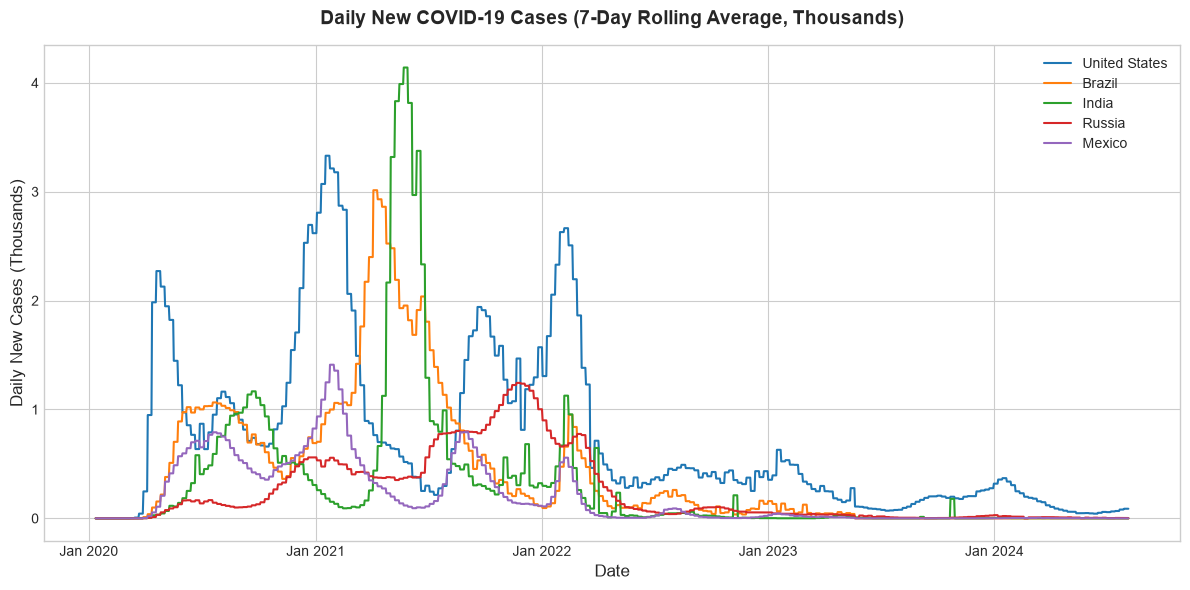

In [14]:
plt.figure(figsize=(12, 6))
for country, col in zip(top5, colors):
    plt.plot(df_rolling['date'], df_rolling[country] / 1e3, label=country, linewidth=1.5, color=col)

plt.title('Daily New COVID-19 Cases (7-Day Rolling Average, Thousands)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily New Cases (Thousands)', fontsize=12)
plt.legend(fontsize=10, loc='upper right')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()

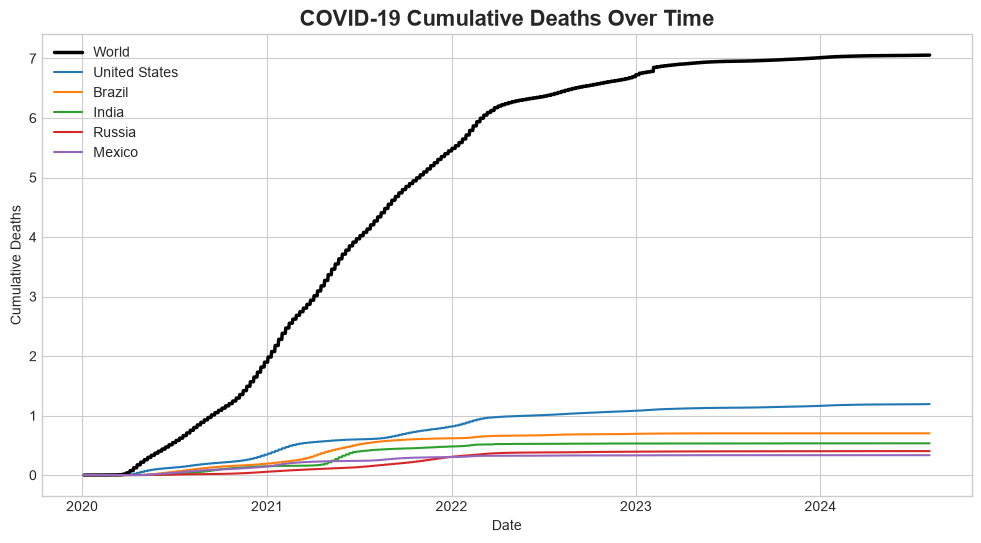

In [ ]:
# Plot COVID-19 deaths over time for the world and top 10 countries
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Calculate daily new cases for World and Top 5 countries
df_daily = df.copy()
numeric_cols = [c for c in df.columns if c != 'date']
df_daily[numeric_cols] = df_daily[numeric_cols].diff().clip(lower=0) # ensure no negative values from reporting adjustments

# 7-day rolling average for smooth plotting
df_rolling = df_daily.copy()
df_rolling[numeric_cols] = df_rolling[numeric_cols].rolling(window=7).mean()

plt.figure(figsize=(12, 6))
plt.plot(df['date'], df['World'] / 1e6, label='World', color='black', linewidth=2.5)
top5 = latest_top10_countries.index[:5]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for country, col in zip(top5, colors):
    plt.plot(df['date'], df[country] / 1e6, label=country, linewidth=1.5, color=col)
plt.xlabel('Date')
plt.ylabel('Cumulative Deaths')
plt.title('COVID-19 Cumulative Deaths Over Time', fontsize=16, fontweight='bold')
plt.legend()

C:\Users\tchin\AppData\Local\Temp\ipykernel_14076\1977933622.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


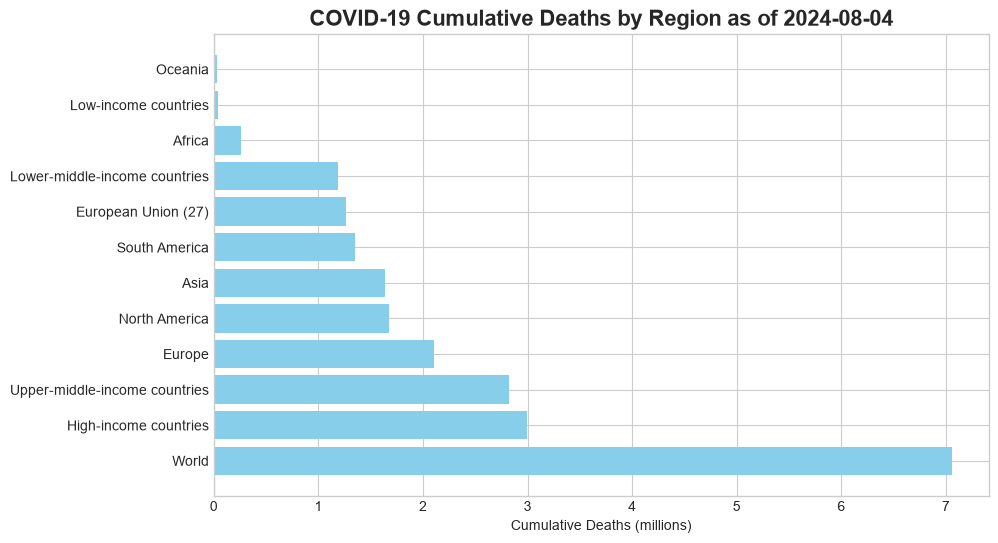

In [13]:
# Plot regional distribution of deaths as of the latest date
plt.figure(figsize=(10, 6))
plt.barh(latest_regions.index, latest_regions.values / 1e6, color='skyblue')
plt.xlabel('Cumulative Deaths (millions)')
plt.title(f'COVID-19 Cumulative Deaths by Region as of {latest_date}', fontsize=16, fontweight='bold')
plt.legend()